# 04 — Artefaktın sübutu və müdafiə yanaşmaları

03-də LR-in ən güclü zərərli siqnallarının boşluq n-gram-ları (`' '`, `' = '`, `' ) '`) olduğu göründü.
Bu notebook iki suala cavab verir:

1. **Bunun formatdan qaynaqlandığını necə bilirik?** — *Artefakt testi*: test dəstinin hər iki sinfi
   semantikanı dəyişmədən "insan formatına" salınır. Model SQL-i öyrənibsə, nəticə dəyişməməlidir.
2. **Həll nədir?** — iki müdafiə və onların birləşməsi:
   - *Normallaşdırma* (`src/normalize.py`): TF-IDF-dən əvvəl kanonik forma
   - *Augmentation*: train-in zərərli sorğularına obfuskasiya nüsxələri əlavə etmək; **leave-one-technique-out**
     (LOTO) ilə modelin görmədiyi texnikaya ümumiləşməsi yoxlanılır

Dataset: `clean_v2` bölgüləri (`train_v2` / `val_v2` / `test_v2`). Hiperparametrlər yalnız validation-da seçilir.
Obfuskasiya dəstləri: `obfuscated_test_v2.csv` (03), ssenari A (middleware, bir dəfə decode) və B (xam trafik). Seed = 42.

## 0. Mühit və məlumatlar

In [1]:
import random
import re
import sys
import time
from pathlib import Path
from urllib.parse import unquote

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import LinearSVC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import obfuscation as obf
from normalize import human_format, normalize, normalize_all, normalize_all_no_punct

PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")

read = lambda name: pd.read_csv(PROC_DIR / name, keep_default_na=False, dtype={"Query": str, "Label": int})
train, val, test = read("train_v2.csv"), read("val_v2.csv"), read("test_v2.csv")
obf_long = pd.read_csv(PROC_DIR / "obfuscated_test_v2.csv", keep_default_na=False)
TECH_ORDER = list(obf.TECHNIQUES) + ["combination"]
SCENARIOS = ["A", "B"]

BASELINE = {
    "LR": joblib.load(MODEL_DIR / "lr_v2.joblib"),
    "SVM": joblib.load(MODEL_DIR / "svm_v2.joblib"),
    "RF": joblib.load(MODEL_DIR / "rf_v2.joblib"),
    "NB": joblib.load(MODEL_DIR / "nb_v2.joblib"),
}
print(f"train {len(train)}, val {len(val)}, test {len(test)}, obfuskasiya sətirləri {len(obf_long)}")

train 21181, val 4535, test 4539, obfuskasiya sətirləri 34310


## 1. Format artefaktı: ikiqat boşluq hansı sinifdədir?
Sorğularda ardıcıl iki və ya daha çox boşluq, həmçinin `=`, `(`, `)` ətrafında boşluq olan sorğuların payı,
sinif üzrə. Əgər bu xüsusiyyətlər demək olar ki, yalnız zərərli sinifdədirsə, model onları "pulsuz" siqnal kimi istifadə edə bilər.

In [2]:
clean_v2 = read("clean_v2.csv")
PATTERNS = {
    "ikiqat boşluq (2+ ardıcıl)": r"  ",
    "' = ' (boşluqlu bərabərlik)": r" = ",
    "'  (  ' (mötərizə ətrafında 2+ boşluq)": r"\s{2,}\(\s{2,}|\s{2,}\)\s{2,}",
    "hər hansı boşluq": r"\s",
}
rows = []
for name, pat in PATTERNS.items():
    for label, cls in ((0, "təmiz"), (1, "zərərli")):
        q = clean_v2.loc[clean_v2.Label == label, "Query"]
        rows.append({"pattern": name, "class": cls, "share_pct": round(q.str.contains(pat, regex=True).mean() * 100, 2)})
format_stats = pd.DataFrame(rows).pivot(index="pattern", columns="class", values="share_pct")[["təmiz", "zərərli"]]
format_stats.to_csv(RES_DIR / "04_format_artifact_stats.csv")
display(format_stats)

class,təmiz,zərərli
pattern,,
' ( ' (mötərizə ətrafında 2+ boşluq),1.01,86.71
' = ' (boşluqlu bərabərlik),14.78,81.06
hər hansı boşluq,69.93,99.24
ikiqat boşluq (2+ ardıcıl),29.81,94.91


## 2. Artefakt testi: "insan formatı"
Test dəstinin **hər iki sinfinə** eyni çevrilmə tətbiq olunur (`normalize.human_format`):
ardıcıl boşluqlar bir boşluğa çevrilir, `(`, `)`, `=`, `,` ətrafındakı boşluqlar silinir.
SQL-də bu simvolların ətrafındakı boşluqlar mənaya təsir etmir, yəni sorğu eyni hücumdur — sadəcə insanın yazdığı formadadır.
(Yeganə istisna — string literalın daxilindəki boşluqlar; bu, sorğunun hücum olub-olmamasını dəyişmir.)

Baza modellər (02 v2) yenidən öyrədilmədən qiymətləndirilir.

In [3]:
test_h = test.assign(Query=test["Query"].map(human_format))
changed = test_h["Query"] != test["Query"]
print("İnsan formatı ilə dəyişən sorğular:")
print(pd.Series({"təmiz": changed[test.Label == 0].mean(), "zərərli": changed[test.Label == 1].mean()})
      .mul(100).round(1).astype(str).add("%").to_string())
print("\nNümunələr:")
for q0, q1 in test.loc[changed & (test.Label == 1), "Query"].sample(4, random_state=SEED).to_frame().assign(
        h=lambda d: d.Query.map(human_format)).itertuples(index=False):
    print(f"  {q0[:90]!r}\n→ {q1[:90]!r}")

def metrics(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "fpr": fp / (fp + tn),
            "tp": tp, "fp": fp, "tn": tn, "fn": fn}

art_rows = []
for m, model in BASELINE.items():
    for ds_name, ds in (("orijinal test", test), ("insan formatı", test_h)):
        art_rows.append({"model": m, "dataset": ds_name, **metrics(ds.Label, model.predict(ds.Query))})
artifact = pd.DataFrame(art_rows)
artifact.to_csv(RES_DIR / "04_artifact_test.csv", index=False)
display(artifact.pivot(index="model", columns="dataset", values=["f1", "recall", "fpr"])
        .loc[list(BASELINE)].style.format("{:.4f}"))

İnsan formatı ilə dəyişən sorğular:
təmiz      48.0%
zərərli    94.7%

Nümunələr:
  '1%" and   (  select 2*  (  if   (    (   select * from   (  select concat  (  0x7171706a71'
→ '1%" and(select 2*(if((select * from(select concat(0x7171706a71,(select(elt(3484=3484,1))),'
  ' select * from users where id  =  1 or 1#", union select \'a\',version  (    )   -- 1'
→ 'select * from users where id=1 or 1#",union select \'a\',version()-- 1'
  '-6496"  )   as obnf where 2903  =  2903 or make_set  (  9354  =  9354,7185  )  --'
→ '-6496")as obnf where 2903=2903 or make_set(9354=9354,7185)--'
  "-1304'  )   union all select 7639#"
→ "-1304')union all select 7639#"


## 3. Ümumi qiymətləndirmə funksiyası
Hər model üçün eyni ölçülər:
- orijinal test dəstində F1 / recall / FPR
- insan formatlı test dəstində F1 / recall / FPR
- hər obfuskasiya texnikası üzrə recall, ssenari A və B-də (03-dəki eyni payload-lar)

In [4]:
def evaluate(model, techniques=TECH_ORDER, with_tests=True):
    out = {}
    if with_tests:
        for ds_name, ds in (("test", test), ("human", test_h)):
            mt = metrics(ds.Label, model.predict(ds.Query))
            for k in ("f1", "recall", "fpr"):
                out[f"{k}_{ds_name}"] = mt[k]
    mal = test.loc[test.Label == 1, "Query"]
    for sc in SCENARIOS:
        inputs = mal.map(unquote) if sc == "A" else mal
        out[f"recall_{sc}_original"] = model.predict(inputs).mean()
        sub = obf_long[(obf_long.scenario == sc) & obf_long.technique.isin(techniques)]
        uniq = pd.unique(sub["model_input"])
        pred = dict(zip(uniq, model.predict(uniq)))
        for tech, g in sub.groupby("technique"):
            out[f"recall_{sc}_{tech}"] = g["model_input"].map(pred).mean()
    return out

def make_vectorizer():
    return TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=True,
                           sublinear_tf=True, min_df=2, dtype=np.float32)

MAKERS = {
    "LR": lambda p: LogisticRegression(C=p, max_iter=2000, random_state=SEED),
    "SVM": lambda p: LinearSVC(C=p, random_state=SEED),
    "RF": lambda p: RandomForestClassifier(n_estimators=p, n_jobs=-1, random_state=SEED),
    "NB": lambda p: MultinomialNB(alpha=p),
}
GRID = {"LR": [1, 10, 100], "SVM": [0.1, 1, 10], "RF": [200], "NB": [0.001, 0.01, 0.1]}

def build(model_name, param, prep=None):
    steps = [("prep", FunctionTransformer(prep))] if prep else []
    steps += [("tfidf", make_vectorizer()), ("clf", MAKERS[model_name](param))]
    return Pipeline(steps)

def fit_tuned(model_name, X, y, prep=None, grid=None):
    """Train one model per grid value, pick by validation F1, return (pipeline, param, val_f1)."""
    best = None
    for p in grid or GRID[model_name]:
        pipe = build(model_name, p, prep).fit(X, y)
        f1 = f1_score(val.Label, pipe.predict(val.Query))
        if best is None or f1 > best[2]:
            best = (pipe, p, f1)
    if model_name == "RF":
        best[0].named_steps["clf"].set_params(n_jobs=1)
    return best

baseline_eval = {m: evaluate(model) for m, model in BASELINE.items()}
print("Baza modellər qiymətləndirildi")

Baza modellər qiymətləndirildi


## 4. Müdafiə 1: normallaşdırma
`src/normalize.py::normalize` TF-IDF-dən əvvəl həm train, həm val/test üçün tətbiq olunur:
1. təkrarlanan URL decode (dəyişiklik qalmayana qədər, maksimum 3 dəfə)
2. MySQL versiyalı şərh açılır: `/*!50000UNION*/` → ` UNION `
3. digər `/* ... */` şərhlər → boşluq
4. bütün whitespace növləri (space, tab, LF, CR, VT, FF) → bir boşluq
5. kiçik hərf
6. `(`, `)`, `=`, `,` ətrafındakı boşluqlar silinir

6-cı addım tapşırıqdakı minimal siyahıya əlavədir: onsuz normallaşdırılmış sorğularda `' = '` və `' ( '` kimi formatlar
qalır və artefakt testi yenə uğursuz ola bilər. Bunu yoxlamaq üçün LR 6-cı addımsız variantla da öyrədilir (ablasiya).

In [5]:
for q in ["1'%0aor%091=1--", "/*!50000union*/ /*!50000select*/ 1,2", "1   )    )    as rbcf where 1053  =  1053",
          "un/**/ion sel/**/ect 1", "1%2527%2520or%25201%253D1"]:
    print(f"{q!r:50} → {normalize(q)!r}")

norm_models, norm_eval, norm_params = {}, {}, {}
for m in MAKERS:
    t0 = time.perf_counter()
    pipe, p, vf1 = fit_tuned(m, train.Query, train.Label, prep=normalize_all)
    norm_models[m], norm_params[m] = pipe, p
    norm_eval[m] = evaluate(pipe)
    print(f"{m:4s} param={p!s:6s} val F1={vf1:.4f}  ({time.perf_counter() - t0:.0f} s)")

pipe, p, vf1 = fit_tuned("LR", train.Query, train.Label, prep=normalize_all_no_punct)
norm_np_eval = evaluate(pipe)
print(f"LR (6-cı addımsız) param={p} val F1={vf1:.4f}")

"1'%0aor%091=1--"                                  → "1' or 1=1--"
'/*!50000union*/ /*!50000select*/ 1,2'             → 'union select 1,2'
'1   )    )    as rbcf where 1053  =  1053'        → '1))as rbcf where 1053=1053'
'un/**/ion sel/**/ect 1'                           → 'un ion sel ect 1'
'1%2527%2520or%25201%253D1'                        → "1' or 1=1"


LR   param=100    val F1=0.9964  (20 s)


SVM  param=1      val F1=0.9961  (19 s)


RF   param=200    val F1=0.9955  (26 s)


NB   param=0.001  val F1=0.9311  (362 s)


LR (6-cı addımsız) param=100 val F1=0.9952


## 5. Müdafiə 2: augmentation və leave-one-technique-out
Train dəstinin **hər zərərli sorğusuna** təsadüfi seçilmiş bir texnika ilə bir obfuskasiya nüsxəsi əlavə olunur
(seed = 42; texnika sorğunu dəyişmirsə, nüsxə əlavə olunmur). Hər sorğu üçün bir nüsxə seçilir ki, train-in
sinif balansı həddən artıq pozulmasın (≈ 7.9k əlavə zərərli sətir). Təmiz sorğulara toxunulmur.

- **Augmentation (görmüş)** — bütün texnikalarla öyrədilmiş bir model (yuxarı hədd, "görülmüş" texnikalar).
- **Augmentation (LOTO)** — hər texnika T üçün ayrıca model: T train-ə qatılmır (kombinasiyalardan da çıxarılır),
  model yalnız T üzərində test olunur. **Əsas göstərici budur** — modelin görmədiyi obfuskasiyaya ümumiləşməsi.
  `combination` üçün LOTO yalnız kombinasiya nümunələrini çıxarır; onun komponentləri ayrıca texnika kimi train-də qalır.

Augmentation bütün müdafiə konfiqurasiyalarında yalnız LR ilə aparılır (əsas model). Hiperparametr (C) tam
augmentation ilə validation-da seçilir və LOTO modellərində eyni saxlanılır.

In [6]:
def augment(train_df, exclude=()):
    pool = [t for t in TECH_ORDER if t not in exclude]
    mal = train_df[train_df.Label == 1].reset_index(drop=True)
    extra = []
    for i, q in enumerate(mal.Query):
        rng = obf.rng_for("augment", i)
        tech = rng.choice(pool)
        if tech == "combination":
            new, _ = obf.combination(q, rng, exclude=exclude)
        else:
            new = obf.TECHNIQUES[tech](q, rng)
        if new != q:
            extra.append(new)
    aug = pd.concat([train_df[["Query", "Label"]], pd.DataFrame({"Query": extra, "Label": 1})], ignore_index=True)
    return aug, len(extra)

aug_full, n_extra = augment(train)
print(f"Augmentation: +{n_extra} zərərli sətir → train {len(aug_full)} sətir, "
      f"zərərli payı {aug_full.Label.mean():.1%} (əvvəl {train.Label.mean():.1%})")

configs = {"aug": None, "both": normalize_all}
full_models, full_eval, full_params = {}, {}, {}
for cfg, prep in configs.items():
    t0 = time.perf_counter()
    pipe, p, vf1 = fit_tuned("LR", aug_full.Query, aug_full.Label, prep=prep)
    full_models[cfg], full_params[cfg] = pipe, p
    full_eval[cfg] = evaluate(pipe)
    print(f"{cfg:5s} (bütün texnikalar) C={p} val F1={vf1:.4f}  ({time.perf_counter() - t0:.0f} s)")

Augmentation: +7093 zərərli sətir → train 28274 sətir, zərərli payı 53.2% (əvvəl 37.5%)


aug   (bütün texnikalar) C=10 val F1=0.9961  (43 s)


both  (bütün texnikalar) C=100 val F1=0.9967  (28 s)


In [7]:
loto_rows = []
for tech in TECH_ORDER:
    aug_t, n_t = augment(train, exclude=(tech,))
    for cfg, prep in configs.items():
        t0 = time.perf_counter()
        pipe = build("LR", full_params[cfg], prep).fit(aug_t.Query, aug_t.Label)
        ev = evaluate(pipe, techniques=[tech])
        loto_rows.append({"held_out": tech, "config": cfg, "n_aug": n_t,
                          **{k: v for k, v in ev.items() if not k.startswith("recall_") or k.endswith(tech)}})
        print(f"LOTO {tech:22s} {cfg:5s} recall A={ev[f'recall_A_{tech}']:.3f} B={ev[f'recall_B_{tech}']:.3f} "
              f"FPR={ev['fpr_test']:.4f}  ({time.perf_counter() - t0:.0f} s)")
loto = pd.DataFrame(loto_rows)
loto.to_csv(RES_DIR / "04_loto_results.csv", index=False)

LOTO random_case            aug   recall A=0.997 B=0.997 FPR=0.0007  (10 s)


LOTO random_case            both  recall A=0.998 B=0.998 FPR=0.0011  (9 s)


LOTO inline_comment_space   aug   recall A=1.000 B=1.000 FPR=0.0007  (10 s)


LOTO inline_comment_space   both  recall A=0.999 B=0.999 FPR=0.0018  (9 s)


LOTO alt_whitespace         aug   recall A=0.822 B=0.822 FPR=0.0011  (12 s)


LOTO alt_whitespace         both  recall A=0.999 B=0.999 FPR=0.0018  (10 s)


... (12 outputs left out)

LOTO keyword_split_comment  aug   recall A=1.000 B=1.000 FPR=0.0007  (12 s)


LOTO keyword_split_comment  both  recall A=0.998 B=0.998 FPR=0.0007  (11 s)


LOTO combination            aug   recall A=1.000 B=1.000 FPR=0.0004  (11 s)


LOTO combination            both  recall A=0.998 B=0.998 FPR=0.0018  (12 s)


### FPR yoxlaması
Augmentation yalnız zərərli sinfə nümunə əlavə edir; bu, modeli `%`, `/**/`, tab kimi simvolları "zərərli" saymağa
itələyə bilər. Ona görə hər konfiqurasiyanın təmiz sorğularda FPR-i (orijinal və insan formatlı test) ayrıca göstərilir;
LOTO modelləri üçün FPR-in diapazonu verilir.

In [8]:
fpr_tab = pd.DataFrame({
    "Baseline": [baseline_eval["LR"]["fpr_test"], baseline_eval["LR"]["fpr_human"]],
    "Normallaşdırma": [norm_eval["LR"]["fpr_test"], norm_eval["LR"]["fpr_human"]],
    "Augmentation (görmüş)": [full_eval["aug"]["fpr_test"], full_eval["aug"]["fpr_human"]],
    "Hər ikisi (görmüş)": [full_eval["both"]["fpr_test"], full_eval["both"]["fpr_human"]],
}, index=["FPR orijinal test", "FPR insan formatı"])
display(fpr_tab.style.format("{:.4%}"))
print(loto.groupby("config")[["fpr_test", "fpr_human"]].agg(["min", "max"]).map(lambda v: f"{v:.4%}").to_string())

,Baseline,Normallaşdırma,Augmentation (görmüş),Hər ikisi (görmüş)
FPR orijinal test,0.1074%,0.1432%,0.1074%,0.0716%
FPR insan formatı,0.1432%,0.1432%,0.1074%,0.0716%


       fpr_test          fpr_human         
            min      max       min      max
config                                     
aug     0.0358%  0.1790%   0.0716%  0.1790%
both    0.0716%  0.4295%   0.0716%  0.4295%


## 6. Yekun cədvəl (LR)
Sətirlərdə texnikalar (recall), sonra ümumi göstəricilər. Sütunlar:
- **Baseline** — 02 v2 LR modeli
- **Normallaşdırma** — `normalize` + LR
- **Augmentation** — LOTO: hər texnika sətri o texnikanı görməmiş modelin nəticəsidir
- **Hər ikisi** — normallaşdırma + augmentation, LOTO
- əlavə: *Norm. (6-cı addımsız)*, *Augmentation (görmüş)*, *Hər ikisi (görmüş)* — müqayisə üçün

Ümumi göstərici sətirlərində (F1/FPR) LOTO sütunları üçün bütün texnikalarla öyrədilmiş model istifadə olunur.
`†` — MySQL-də etibarsız, `‡` — yalnız ikiqat decode edən tətbiqdə işləyir.

In [9]:
loto_idx = loto.set_index(["held_out", "config"])
METRIC_ROWS = [("F1 — orijinal test", "f1_test"), ("Recall — orijinal test", "recall_test"),
               ("FPR — orijinal test", "fpr_test"), ("F1 — insan formatı", "f1_human"),
               ("Recall — insan formatı", "recall_human"), ("FPR — insan formatı", "fpr_human")]
MARK = {"keyword_split_comment": " †", "double_url_encode": " ‡"}

def defense_table(sc):
    cols = {"Baseline": [], "Normallaşdırma": [], "Augmentation (LOTO)": [], "Hər ikisi (LOTO)": [],
            "Norm. (6-cı addımsız)": [], "Augmentation (görmüş)": [], "Hər ikisi (görmüş)": []}
    index = []
    def add(label, key, loto_key=None):
        index.append(label)
        cols["Baseline"].append(baseline_eval["LR"][key])
        cols["Normallaşdırma"].append(norm_eval["LR"][key])
        cols["Norm. (6-cı addımsız)"].append(norm_np_eval[key])
        cols["Augmentation (görmüş)"].append(full_eval["aug"][key])
        cols["Hər ikisi (görmüş)"].append(full_eval["both"][key])
        for cfg, col in (("aug", "Augmentation (LOTO)"), ("both", "Hər ikisi (LOTO)")):
            cols[col].append(loto_idx.loc[(loto_key, cfg), key] if loto_key else full_eval[cfg][key])
    add("original (recall)", f"recall_{sc}_original")
    for tech in TECH_ORDER:
        add(tech + MARK.get(tech, ""), f"recall_{sc}_{tech}", loto_key=tech)
    for label, key in METRIC_ROWS:
        add(label, key)
    return pd.DataFrame(cols, index=index)

tables = {sc: defense_table(sc) for sc in SCENARIOS}
long_rows = []
for sc, t in tables.items():
    print(f"===== Ssenari {sc} — {'middleware (bir dəfə decode)' if sc == 'A' else 'xam trafik'} =====")
    display(t.style.format("{:.4f}"))
    long_rows.append(t.reset_index(names="row").melt(id_vars="row", var_name="config", value_name="value")
                     .assign(scenario=sc, model="LR"))
defense = pd.concat(long_rows, ignore_index=True)[["scenario", "model", "row", "config", "value"]]
defense["value"] = defense["value"].astype(float).round(5)
defense.to_csv(RES_DIR / "defense_results.csv", index=False)
for sc, t in tables.items():
    t.to_csv(RES_DIR / f"04_defense_table_{sc}.csv")

===== Ssenari A — middleware (bir dəfə decode) =====


,Baseline,Normallaşdırma,Augmentation (LOTO),Hər ikisi (LOTO),Norm. (6-cı addımsız),Augmentation (görmüş),Hər ikisi (görmüş)
original (recall),0.9960,0.9948,0.9931,0.9937,0.9960,0.9931,0.9937
random_case,1.0000,0.9988,0.9971,0.9977,1.0000,0.9971,0.9977
inline_comment_space,1.0000,0.9988,1.0000,0.9988,1.0000,1.0000,0.9977
alt_whitespace,0.7777,0.9988,0.8216,0.9988,1.0000,0.9994,0.9977
alt_whitespace_url,0.7777,0.9988,0.9994,0.9988,1.0000,0.9994,0.9977
url_encode,0.9989,0.9977,0.9966,0.9983,0.9989,0.9960,0.9966
double_url_encode ‡,0.9839,0.9977,0.9977,0.9983,0.9989,1.0000,0.9966
versioned_comment,1.0000,0.9988,1.0000,0.9988,1.0000,1.0000,0.9977
logical_operator,1.0000,1.0000,0.9981,0.9981,1.0000,0.9981,1.0000
hex_strings,0.9984,1.0000,0.9936,0.9968,0.9984,0.9952,0.9984


===== Ssenari B — xam trafik =====


,Baseline,Normallaşdırma,Augmentation (LOTO),Hər ikisi (LOTO),Norm. (6-cı addımsız),Augmentation (görmüş),Hər ikisi (görmüş)
original (recall),0.9960,0.9948,0.9931,0.9937,0.9960,0.9931,0.9937
random_case,1.0000,0.9988,0.9971,0.9977,1.0000,0.9971,0.9977
inline_comment_space,1.0000,0.9988,1.0000,0.9988,1.0000,1.0000,0.9977
alt_whitespace,0.7777,0.9988,0.8216,0.9988,1.0000,0.9994,0.9977
alt_whitespace_url,0.7639,0.9988,0.9954,0.9988,1.0000,1.0000,0.9977
url_encode,0.9839,0.9977,1.0000,0.9983,0.9989,1.0000,0.9966
double_url_encode ‡,0.3994,0.9977,0.9868,0.9983,0.9989,1.0000,0.9966
versioned_comment,1.0000,0.9988,1.0000,0.9988,1.0000,1.0000,0.9977
logical_operator,1.0000,1.0000,0.9981,0.9981,1.0000,0.9981,1.0000
hex_strings,0.9984,1.0000,0.9936,0.9968,0.9984,0.9952,0.9984


Bütün modellər üçün normallaşdırmanın təsiri (artefakt testi və ssenari A recall-u), baza ilə müqayisədə.

In [10]:
rows = []
for m in MAKERS:
    for cfg, ev in (("Baseline", baseline_eval[m]), ("Normallaşdırma", norm_eval[m])):
        rows.append({"model": m, "config": cfg, "F1 test": ev["f1_test"], "FPR test": ev["fpr_test"],
                     "F1 insan formatı": ev["f1_human"], "FPR insan formatı": ev["fpr_human"],
                     "min recall A": min(ev[f"recall_A_{t}"] for t in TECH_ORDER),
                     "orta recall A": np.mean([ev[f"recall_A_{t}"] for t in TECH_ORDER])})
all_models = pd.DataFrame(rows).set_index(["model", "config"])
all_models.to_csv(RES_DIR / "04_normalization_all_models.csv")
display(all_models.style.format("{:.4f}"))

## 7. Qrafik: ssenari A, LR konfiqurasiyaları

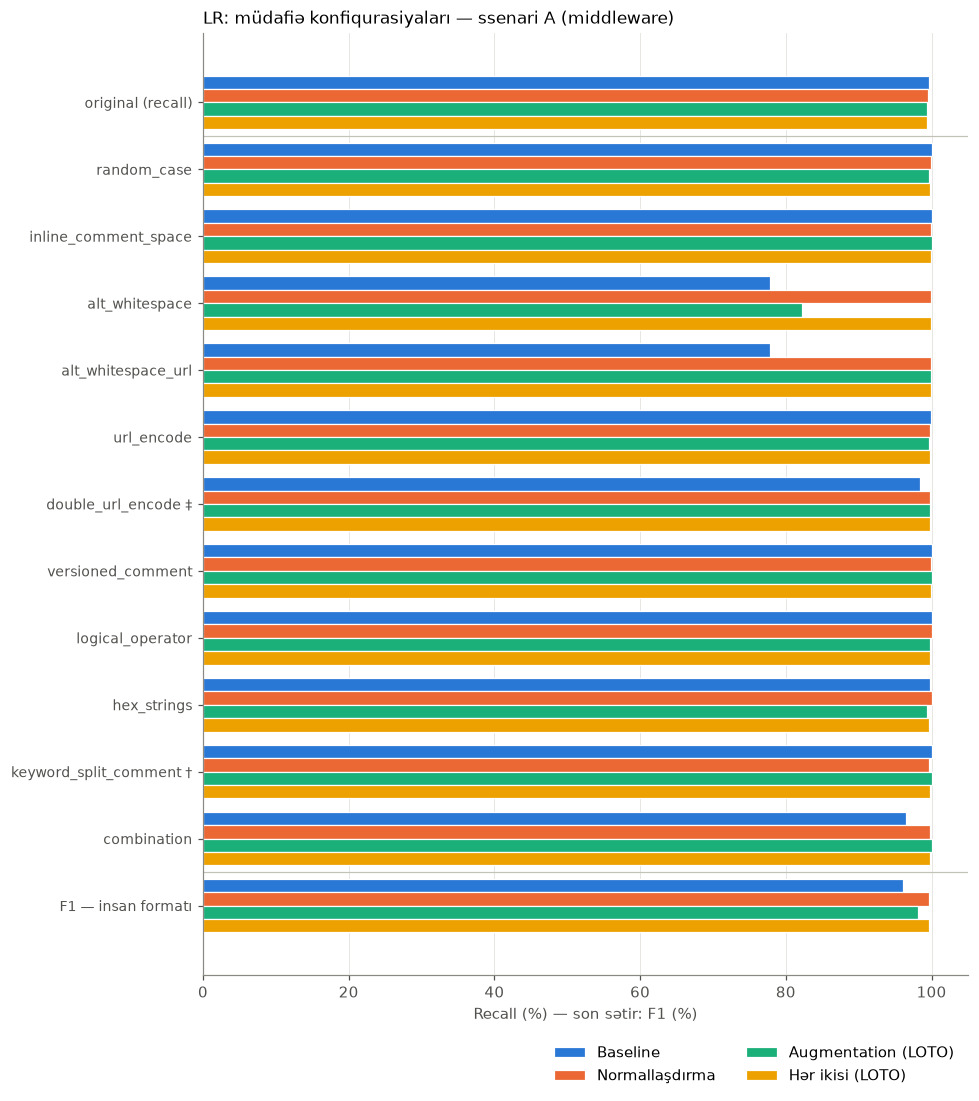

In [11]:
CFG_COLORS = {"Baseline": "#2a78d6", "Normallaşdırma": "#eb6834", "Augmentation (LOTO)": "#1baf7a",
              "Hər ikisi (LOTO)": "#eda100"}
t = tables["A"]
rows_plot = ["original (recall)"] + [r for r in t.index if r.split(" ")[0] in TECH_ORDER] + \
            ["F1 — insan formatı"]
y = np.arange(len(rows_plot))[::-1]
h = 0.2
fig, ax = plt.subplots(figsize=(9, 10))
for k, (cfg, color) in enumerate(CFG_COLORS.items()):
    ax.barh(y + (1.5 - k) * h, t.loc[rows_plot, cfg] * 100, height=h, color=color, label=cfg,
            edgecolor="white", linewidth=0.8)
ax.set_yticks(y, rows_plot, fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel("Recall (%) — son sətir: F1 (%)")
ax.set_title("LR: müdafiə konfiqurasiyaları — ssenari A (middleware)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.axhline(y[0] - 0.5, color="#c3c2b7", linewidth=0.8)
ax.axhline(y[-1] + 0.5, color="#c3c2b7", linewidth=0.8)
ax.legend(frameon=False, loc="lower right", ncol=2, bbox_to_anchor=(1, -0.13))
fig.tight_layout()
save_fig(fig, "04_defense_recall_A.png")
plt.show()

## 8. Middleware üçün modelin saxlanması
5-ci mərhələdə (Express middleware) istifadə üçün **normallaşdırma + augmentation (bütün texnikalar)** LR modeli
saxlanılır. Pipeline xam sorğu qəbul edir; `normalize` daxildədir (`src/` yolu import zamanı lazımdır).

In [12]:
joblib.dump(full_models["both"], MODEL_DIR / "lr_norm_aug_v2.joblib", compress=3)
joblib.dump(norm_models["LR"], MODEL_DIR / "lr_norm_v2.joblib", compress=3)
print("Saxlanıldı: models/lr_norm_aug_v2.joblib, models/lr_norm_v2.joblib")

Saxlanıldı: models/lr_norm_aug_v2.joblib, models/lr_norm_v2.joblib
